## Download Dataset from Kaggle

In [ ]:
%%capture
!pip install kaggle

In [ ]:
# Make sure the kaggle.json file is uploaded to the Colab environment
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/

mv: cannot stat 'kaggle.json': No such file or directory


In [ ]:
import pandas as pd
import os

KAGGLE_DATASET = 'shayanfazeli/heartbeat'

# Create a directory for the dataset
dataset_name = KAGGLE_DATASET.split('/')[-1]
!mkdir -p {dataset_name}

# Download the dataset
!kaggle datasets download -d {KAGGLE_DATASET} -p {dataset_name}

# Unzip the downloaded files (assuming it's a zip file)
# Check the contents of the directory to find the actual CSV/data file name
import zipfile
for item in os.listdir(dataset_name):
    if item.endswith('.zip'):
        file_path = os.path.join(dataset_name, item)
        with zipfile.ZipFile(file_path, 'r') as zip_ref:
            zip_ref.extractall(dataset_name)
        os.remove(file_path) # Remove the zip file after extraction

# List files in the extracted directory to identify the data file
print(f"Files in {dataset_name}: {os.listdir(dataset_name)}")

# Assuming the main data file is a CSV and you know its name, or it's the only one
# You might need to adjust this part based on the specific dataset's file structure
csv_files = [f for f in os.listdir(dataset_name) if f.endswith('.csv')]
if csv_files:
    data_file_path = os.path.join(dataset_name, csv_files[0])
    df = pd.read_csv(data_file_path)
    print(f"Successfully loaded {csv_files[0]} into a DataFrame.")
    display(df.head())
else:
    print("No CSV files found in the extracted dataset. Please check the dataset's content.")


Dataset URL: https://www.kaggle.com/datasets/shayanfazeli/heartbeat
License(s): unknown
100% 98.8M/98.8M [00:01<00:00, 96.8MB/s]

Files in heartbeat: ['mitbih_test.csv', 'ptbdb_abnormal.csv', 'mitbih_train.csv', 'ptbdb_normal.csv']
Successfully loaded mitbih_test.csv into a DataFrame.


,1.000000000000000000e+00,7.582644820213317871e-01,1.115702465176582336e-01,0.000000000000000000e+00,8.057851344347000122e-02,7.851240038871765137e-02,6.611569970846176147e-02,4.958677664399147034e-02,4.752065986394882202e-02,3.512396663427352905e-02,...,0.000000000000000000e+00.56,0.000000000000000000e+00.57,0.000000000000000000e+00.58,0.000000000000000000e+00.59,0.000000000000000000e+00.60,0.000000000000000000e+00.61,0.000000000000000000e+00.62,0.000000000000000000e+00.63,0.000000000000000000e+00.64,0.000000000000000000e+00.65
0,0.908425,0.783883,0.531136,0.362637,0.366300,0.344322,0.333333,0.307692,0.296703,0.300366,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.730088,0.212389,0.000000,0.119469,0.101770,0.101770,0.110619,0.123894,0.115044,0.132743,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.910417,0.681250,0.472917,0.229167,0.068750,0.000000,0.004167,0.014583,0.054167,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.570470,0.399329,0.238255,0.147651,0.000000,0.003356,0.040268,0.080537,0.070470,0.090604,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.000000,0.923664,0.656489,0.195929,0.111959,0.175573,0.122137,0.050891,0.035623,0.055980,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#Task Description
We need to use two models, the first one to determine if the heartbeat is normal or abnormal, the second one to determine the kind of abnormality

## Steps
1. Read both train and test csv file (df_train and df_test)

2. Split df_train into df_train_normal and df_train_abnormal

3. split df_train_normal and df_train_abnormal into
- df_train_normal_train
- df_train_normal_test
- df_train_abnormal_train
- df_train_abnormal_test

4. Create an auto-encoder model and train it on df_train_normal_train

5. Test the model using df_test_mix which is a combination of df_train_normal_test and df_train_abnormal

6. do a classification report for normal and abnormal classes

7. Create another simple NN model

8. Train and test it using df_train_abnormal_train and df_train_abnormal_test

9. do a classification report for all the classes

In [ ]:
df_train = pd.read_csv('heartbeat/mitbih_train.csv', header=None)
df_test = pd.read_csv('heartbeat/mitbih_test.csv', header=None)
display(df_train.head())

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
df_train.nunique()

,0
0,23408
1,42845
2,49611
3,41007
4,39328
...,...
183,920
184,843
185,778
186,748


In [ ]:
# Create df_train_normal for rows where column 187 is 1
df_train_normal = df_train[df_train[187] == 0]
display(df_train_normal.head())

# Create df_train_abnormal for rows where column 187 is not 1
df_train_abnormal = df_train[df_train[187] != 0]
display(df_train_abnormal.head())

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
72471,1.000000,0.666667,0.100457,0.036530,0.073059,0.050228,0.018265,0.105023,0.132420,0.091324,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1.0
72472,0.983696,1.000000,0.331522,0.000000,0.108696,0.163043,0.130435,0.190217,0.288043,0.222826,...,0.461957,0.483696,0.500000,0.494565,0.510870,0.51087,0.505435,0.472826,0.434783,1.0
72473,1.000000,0.911504,0.216814,0.000000,0.101770,0.199115,0.176991,0.194690,0.252212,0.238938,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1.0
72474,0.090498,0.126697,0.217195,0.361991,0.461538,0.556561,0.443439,0.434389,0.452489,0.511312,...,0.122172,0.131222,0.140271,0.158371,0.176471,0.20362,0.212670,0.000000,0.000000,1.0
72475,0.961111,1.000000,0.551852,0.101852,0.040741,0.085185,0.094444,0.088889,0.085185,0.070370,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1.0


In [ ]:
from sklearn.model_selection import train_test_split

X_train_normal = df_train_normal.drop(columns=[187]) # Features are all columns except 187
y_train_normal = df_train_normal[187]              # Target is column 187
X_train_abnormal = df_train_abnormal.drop(columns=[187]) # Features are all columns except 187
y_train_abnormal = df_train_abnormal[187]
X_test = df_test.drop(columns=[187])
y_test = df_test[187]

X_train_abnormal_train, X_train_abnormal_test, y_train_abnormal_train, y_train_abnormal_test = train_test_split(X_train_abnormal, y_train_abnormal, test_size=0.2, random_state=42, stratify=y_train_abnormal)

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Define the input shape for the autoencoder (number of features)
input_dim = X_train_normal.shape[1]

# Encoder architecture
encoder_input = keras.Input(shape=(input_dim,))
encoded = layers.Dense(128, activation='relu')(encoder_input)
encoded = layers.Dense(64, activation='relu')(encoded)
encoded = layers.Dense(32, activation='relu')(encoded)

# Decoder architecture
decoded = layers.Dense(64, activation='relu')(encoded)
decoded = layers.Dense(128, activation='relu')(decoded)
decoded = layers.Dense(input_dim, activation='sigmoid')(decoded) # Output layer matches input_dim

# Create the autoencoder model
autoencoder = keras.Model(encoder_input, decoded)

# Compile the autoencoder
autoencoder.compile(optimizer='adam', loss='mean_squared_error')

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 187)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        24,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 187)            │        24,123 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 68,955 (269.36 KB)

 Trainable params: 68,955 (269.36 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the autoencoder
history = autoencoder.fit(
    X_train_normal, X_train_normal, # Input and target are the same for autoencoders
    epochs=50,                       # Number of training epochs
    batch_size=256,                  # Batch size for training
    shuffle=True,                    # Shuffle data before each epoch
    validation_split=0.2,            # Use 20% of the training data for validation
    verbose=1                        # Display training progress
)

print("Autoencoder training complete!")

Epoch 1/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0307 - val_loss: 0.0099
Epoch 2/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0080 - val_loss: 0.0064
Epoch 3/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0052 - val_loss: 0.0044
Epoch 4/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0039 - val_loss: 0.0035
Epoch 5/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0033 - val_loss: 0.0031
Epoch 6/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0029 - val_loss: 0.0027
Epoch 7/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0026 - val_loss: 0.0024
Epoch 8/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0023 - val_loss: 0.0023
Epoch 9/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0021 - val_loss: 0.0021
Epoch 10/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0020 - val_loss: 0.0020
Epoch 11/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0019 - val_loss: 0.0020
Epoch 12/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/st

In [ ]:
# Combine the test feature sets
X_test_mixed = pd.concat([X_train_abnormal, X_test])

# Combine the test label sets
y_test_mixed = pd.concat([y_train_abnormal, y_test])

print(f"Shape of combined mixed test features (X_test_mixed): {X_test_mixed.shape}")
print(f"Shape of combined mixed test labels (y_test_mixed): {y_test_mixed.shape}")

# Display the head of the combined datasets
print("\nX_test_mixed head:")
display(X_test_mixed.head())

print("\ny_test_mixed head:")
display(y_test_mixed.head())

Shape of combined mixed test features (X_test_mixed): (36975, 187)
Shape of combined mixed test labels (y_test_mixed): (36975,)

X_test_mixed head:


,0,1,2,3,4,5,6,7,8,9,...,177,178,179,180,181,182,183,184,185,186
72471,1.000000,0.666667,0.100457,0.036530,0.073059,0.050228,0.018265,0.105023,0.132420,0.091324,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
72472,0.983696,1.000000,0.331522,0.000000,0.108696,0.163043,0.130435,0.190217,0.288043,0.222826,...,0.483696,0.461957,0.483696,0.500000,0.494565,0.510870,0.51087,0.505435,0.472826,0.434783
72473,1.000000,0.911504,0.216814,0.000000,0.101770,0.199115,0.176991,0.194690,0.252212,0.238938,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
72474,0.090498,0.126697,0.217195,0.361991,0.461538,0.556561,0.443439,0.434389,0.452489,0.511312,...,0.113122,0.122172,0.131222,0.140271,0.158371,0.176471,0.20362,0.212670,0.000000,0.000000
72475,0.961111,1.000000,0.551852,0.101852,0.040741,0.085185,0.094444,0.088889,0.085185,0.070370,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000



y_test_mixed head:


,187
72471,1.0
72472,1.0
72473,1.0
72474,1.0
72475,1.0


In [ ]:
# Calculate reconstruction errors for the mixed test set
reconstructions_mixed = autoencoder.predict(X_test_mixed)
reconstruction_error_mixed = tf.reduce_mean(tf.square(X_test_mixed - reconstructions_mixed), axis=1)

# Add the true labels back to the reconstruction errors for analysis
error_df_mixed = pd.DataFrame({'reconstruction_error': reconstruction_error_mixed.numpy(),
                               'true_class': y_test_mixed})

print("Reconstruction errors calculated for the mixed test set.")
display(error_df_mixed.head())

1156/1156 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
Reconstruction errors calculated for the mixed test set.


,reconstruction_error,true_class
72471,0.000546,1.0
72472,0.004658,1.0
72473,0.001037,1.0
72474,0.011220,1.0
72475,0.000264,1.0


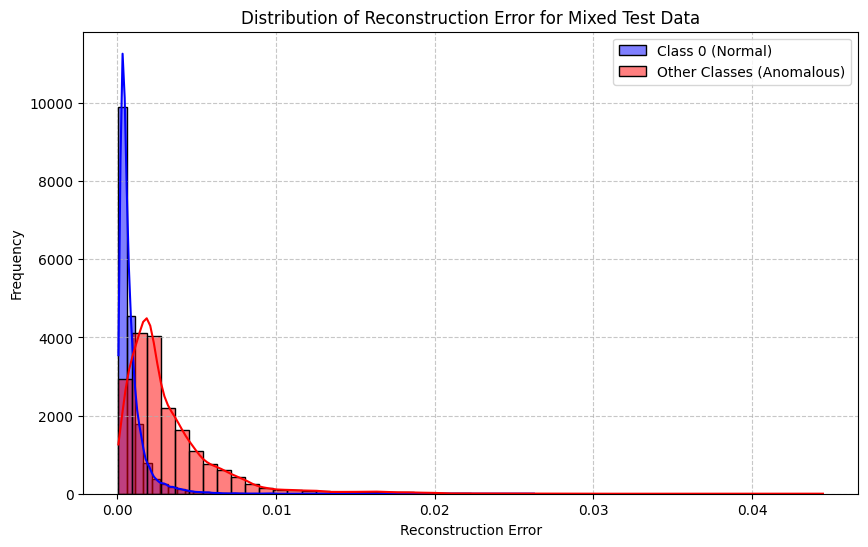

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting the distribution of reconstruction errors for normal and other classes
plt.figure(figsize=(10, 6))
sns.histplot(error_df_mixed.loc[error_df_mixed['true_class'] == 0, 'reconstruction_error'],
             bins=50, kde=True, color='blue', label='Class 0 (Normal)')
sns.histplot(error_df_mixed.loc[error_df_mixed['true_class'] != 0, 'reconstruction_error'],
             bins=50, kde=True, color='red', label='Other Classes (Anomalous)')
plt.title('Distribution of Reconstruction Error for Mixed Test Data')
plt.xlabel('Reconstruction Error')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
# Recalculate reconstruction errors and create error_df_mixed
reconstructions_mixed = autoencoder.predict(X_test_mixed)
reconstruction_error_mixed = tf.reduce_mean(tf.square(X_test_mixed - reconstructions_mixed), axis=1)

# Add the true labels back to the reconstruction errors for analysis
error_df_mixed = pd.DataFrame({
    'reconstruction_error': reconstruction_error_mixed.numpy(),
    'true_class': y_test_mixed
})

print("Reconstruction errors and error_df_mixed have been re-calculated and created.")
display(error_df_mixed.head())

1156/1156 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
Reconstruction errors and error_df_mixed have been re-calculated and created.


,reconstruction_error,true_class
72471,0.000546,1.0
72472,0.004658,1.0
72473,0.001037,1.0
72474,0.011220,1.0
72475,0.000264,1.0


Based on the histogram, we can choose a threshold to differentiate between 'normal' (class 0) and 'anomalous' (other classes) data. A common approach is to set the threshold based on the maximum reconstruction error observed for the normal class in the *training* set, or a certain percentile. For demonstration purposes, let's pick a threshold visually from the plot.

In [ ]:
import numpy as np

In [ ]:
threshold = np.percentile(error_df_mixed.loc[error_df_mixed['true_class'] == 0, 'reconstruction_error'], 60)
print(f"Calculated threshold based on 99th percentile of Class 0 errors: {threshold:.4f}")
error_df_mixed['prediction'] = (error_df_mixed['reconstruction_error'] > threshold).astype(int)

# Evaluate the anomaly detection performance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# For anomaly detection, 'true_class' != 0 indicates anomaly (1), 'true_class' == 0 indicates normal (0)
# We need to convert y_test_mixed to binary labels for evaluation: 0 for normal, 1 for anomaly
binary_true_labels = (error_df_mixed['true_class'] != 0).astype(int)

print("\nClassification Report (Normal vs. Abnormal):\n")
print(classification_report(binary_true_labels, error_df_mixed['prediction'],
                            labels=[0, 1],
                            target_names=['Normal', 'Abnormal'],
                            zero_division=0))

Calculated threshold based on 99th percentile of Class 0 errors: 0.0007

Classification Report (Normal vs. Abnormal):

              precision    recall  f1-score   support

      Normal       0.86      0.60      0.71     18118
    Abnormal       0.70      0.91      0.79     18857

    accuracy                           0.76     36975
   macro avg       0.78      0.75      0.75     36975
weighted avg       0.78      0.76      0.75     36975



In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Initialize the RandomForestClassifier
# You might need to tune hyperparameters like n_estimators, max_depth, etc.
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# Train the model on the 'other classes' training data
model.fit(X_train_abnormal_train, y_train_abnormal_train)

print("RandomForestClassifier training complete!")

RandomForestClassifier training complete!


In [ ]:
# Make predictions on the 'other classes' test data
y_train_abnormal_pred = model.predict(X_train_abnormal_test)

# Evaluate the model
print("\nClassification Report for Minor Classes:")
print(classification_report(y_train_abnormal_test, y_train_abnormal_pred))


Classification Report for Minor Classes:
              precision    recall  f1-score   support

         1.0       0.97      0.93      0.95       445
         2.0       0.95      0.98      0.97      1158
         3.0       0.93      0.81      0.87       128
         4.0       0.99      0.99      0.99      1286

    accuracy                           0.97      3017
   macro avg       0.96      0.93      0.94      3017
weighted avg       0.97      0.97      0.97      3017



In [ ]:
import numpy as np
from sklearn.metrics import classification_report
import pandas as pd

print("Applying the combined model to X_test and y_test...")

# 1. Calculate reconstruction errors for the X_test set using the trained autoencoder
reconstructions_test = autoencoder.predict(X_test)
reconstruction_error_test = tf.reduce_mean(tf.square(X_test - reconstructions_test), axis=1)

# Create an error DataFrame for X_test
error_df_test = pd.DataFrame({
    'reconstruction_error': reconstruction_error_test.numpy(),
    'true_class': y_test
})

# 2. Apply the anomaly detection threshold
# Use the 'threshold' calculated previously from the mixed test set, or a new one based on X_train_normal
# For consistency with the last calculated threshold, we'll use it here.
# The threshold variable from cell '853a39bf' is: threshold = np.float64(0.0011810509044659595)
# If you prefer to recalculate from X_train_normal:
# threshold_from_train_normal = np.percentile(reconstruction_error_normal_train, 80) # where reconstruction_error_normal_train are errors from X_train_normal

error_df_test['prediction_ad'] = (error_df_test['reconstruction_error'] > threshold).astype(int)

# Initialize an array for final combined predictions for y_test
final_predictions_for_test = np.full(len(y_test), -1.0)

# 3. Assign class 0 to instances predicted as normal by the autoencoder
normal_indices_test = error_df_test[error_df_test['prediction_ad'] == 0].index
final_predictions_for_test[normal_indices_test] = 0.0

# 4. For instances predicted as abnormal by the autoencoder, use the RandomForestClassifier
abnormal_indices_test = error_df_test[error_df_test['prediction_ad'] == 1].index

if len(abnormal_indices_test) > 0:
    # Extract corresponding features from X_test for these abnormal instances
    X_abnormal_subset_test = X_test.iloc[abnormal_indices_test]

    # Predict specific minor classes using the trained RandomForestClassifier
    minor_class_predictions_test = model.predict(X_abnormal_subset_test)

    # Assign these predictions to the final_predictions_for_test array
    final_predictions_for_test[abnormal_indices_test] = minor_class_predictions_test
else:
    print("No instances in X_test were predicted as abnormal by the autoencoder.")

# Ensure all predictions are assigned
if np.any(final_predictions_for_test == -1.0):
    print("Warning: Some predictions in X_test were not assigned a class.")

print("Combined predictions for X_test generated.")

# Convert true and predicted labels to integer for classification report
true_labels_test_int = y_test.astype(int)
predicted_labels_test_int = final_predictions_for_test.astype(int)

# Get all possible unique classes from the true test labels
all_possible_classes_test = sorted(true_labels_test_int.unique())

# 5. Generate the full classification report for all classes
print("\nFull Classification Report for X_test (All Classes):\n")
print(classification_report(true_labels_test_int, predicted_labels_test_int,
                            labels=all_possible_classes_test,
                            zero_division=0))

Applying the combined model to X_test and y_test...
685/685 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Combined predictions for X_test generated.

Full Classification Report for X_test (All Classes):

              precision    recall  f1-score   support

           0       0.97      0.60      0.74     18118
           1       0.11      0.79      0.19       556
           2       0.28      0.92      0.43      1448
           3       0.27      0.09      0.14       162
           4       0.85      0.96      0.90      1608

    accuracy                           0.65     21892
   macro avg       0.49      0.67      0.48     21892
weighted avg       0.89      0.65      0.71     21892

